# KAM theory, Poincaré–Birkhoff, Diophantine frequencies and the golden torus

> **Note.** This notebook is a conceptual companion to the kicked-top simulation in this repository
> (`src/`, `config.nml`, `README.md`). For the simplest illustrations it uses the **standard (Chirikov) map**
> instead of the kicked top. It is fully self-contained: it needs only `numpy` and `matplotlib`
> and does not use the Fortran build or its output.

**Why the standard map?** The kicked top (Haake convention, see `README.md`) is an area-preserving map of the
sphere, shown in the canonical coordinates $(\phi, Z=\cos\theta)$. Its parameters in `config.nml` are the rotation
angle $p$ and the torsion strength $k$ (default $p=\pi/2$, $k=3$, a mixed phase space with islands and chaos).
For small $p$ and $k$ the top is close to the continuous flow of the effective Hamiltonian $pY + \tfrac12 k Z^2$,
which is integrable; increasing $k$ perturbs it. Exactly the same scenario — an integrable map plus a periodic kick of
tunable strength — is realised by the standard map with a single parameter $K$, on a flat cylinder instead of a sphere.
Everything below (surviving tori, island chains, chaos) is seen in the kicked-top phase portraits as well.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

TWO_PI = 2 * np.pi

## 1. KAM theory

### Integrable systems and invariant tori

Consider a Hamiltonian system with $d$ degrees of freedom written in **action–angle variables**
$(\mathbf I, \boldsymbol\theta)$, where $\mathbf I = (I_1,\dots,I_d)$ are the actions and
$\boldsymbol\theta = (\theta_1,\dots,\theta_d)$, each $\theta_j \in [0, 2\pi)$, are the conjugate angles.
If the Hamiltonian depends on the actions only, $H = H_0(\mathbf I)$, the system is **integrable**. Hamilton's equations are

$$
\dot{\mathbf I} = -\frac{\partial H_0}{\partial \boldsymbol\theta} = 0,
\qquad
\dot{\boldsymbol\theta} = \frac{\partial H_0}{\partial \mathbf I} \equiv \boldsymbol\omega(\mathbf I),
$$

so $\mathbf I(t) = \mathbf I(0)$ and $\boldsymbol\theta(t) = \boldsymbol\theta(0) + \boldsymbol\omega(\mathbf I)\,t$.
Here $\boldsymbol\omega(\mathbf I)$ is the vector of frequencies. For fixed $\mathbf I$ the angles sweep out a
$d$-dimensional torus $\{\mathbf I = \text{const}\}$; it is **invariant** because a trajectory that starts on it stays on it.
Phase space is foliated into such nested tori.

* If the frequencies are **rationally dependent** (a *resonance*: $\mathbf m\cdot\boldsymbol\omega = 0$ for some nonzero
  integer vector $\mathbf m$), trajectories on the torus are periodic (or fill only a lower-dimensional subset).
  The torus is called *resonant*.
* If they are **rationally independent**, each trajectory densely fills its torus (*quasi-periodic motion*).

### Perturbation

Now add a small perturbation of strength $\varepsilon$ that depends on the angles:

$$
H(\mathbf I, \boldsymbol\theta) = H_0(\mathbf I) + \varepsilon\, H_1(\mathbf I, \boldsymbol\theta),
\qquad 0 < \varepsilon \ll 1 .
$$

Then $\dot{\mathbf I} = -\varepsilon\,\partial H_1/\partial\boldsymbol\theta \neq 0$, so the actions are no longer conserved
and it is not obvious that any torus survives.

**KAM theorem** (Kolmogorov 1954, Arnold 1963, Moser 1962). Assume $H_0$ is *non-degenerate*,
$\det\left(\partial^2 H_0/\partial I_i\partial I_j\right) \neq 0$ (the frequencies change with the actions, a "twist"),
and $H_1$ is sufficiently smooth. Then for small enough $\varepsilon$:

* tori whose frequencies are **sufficiently irrational** (the *Diophantine* condition of Sec. 3) **survive**, only slightly
  deformed, and carry quasi-periodic motion with the same frequencies;
* **resonant** tori, and tori whose frequencies are too close to resonant, are **destroyed**: they break into chains of
  islands and thin chaotic layers (Sec. 2);
* the surviving tori occupy most of phase space: the destroyed fraction goes to zero as $\varepsilon \to 0$.

As $\varepsilon$ grows, more and more tori break, and eventually large chaotic regions appear.

### A concrete example: the standard map

The kicked rotor is a free rotor with angle $\theta$ and angular momentum $I$, kicked once per unit time:

$$
H(I,\theta,t) = \frac{I^2}{2} + K\cos\theta \sum_{n=-\infty}^{\infty} \delta(t-n),
$$

where $\delta$ is the Dirac delta function and $K$ is the kick strength. Between kicks $H = I^2/2$, so
$\dot I = 0$ and $\dot\theta = I$. Across a kick, integrating $\dot I = -\partial H/\partial\theta = K\sin\theta\sum_n\delta(t-n)$
from just before to just after $t=n$ gives the jump $I \to I + K\sin\theta$ ($\theta$ does not jump since $\dot\theta = I$ is finite).
Recording $(\theta, I)$ just after each kick and then letting the rotor rotate freely for one unit of time gives the
**standard map**

$$
I' = I + K\sin\theta, \qquad \theta' = \theta + I' \pmod{2\pi}.
$$

Both variables can be taken modulo $2\pi$ (the map is periodic in $I$ with period $2\pi$). The map is area-preserving:
its Jacobian matrix has determinant $1$, like the kicked top in $(\phi, Z)$. Recording the state once per period is a
**Poincaré section**: a $d=2$ torus (here: rotor angle and time) appears as a curve.

* $K = 0$: $I$ is conserved and $\theta$ advances by $I$ each step. Every horizontal line $I=\text{const}$ is an invariant
  curve (a torus) with **winding number** $\omega = I/2\pi$ (the fraction of a full turn per step).
* small $K$: most curves survive slightly deformed (KAM); near rational $\omega = n/m$ small island chains appear.
* $K \approx 1$: the last spanning curve (with golden-mean winding, Sec. 4) breaks at $K_c \approx 0.9716$
  (Greene 1979), and chaotic orbits can wander over all $I$.

The figure iterates the map for a grid of initial conditions at $K = 0,\ 0.5,\ 1.0$.

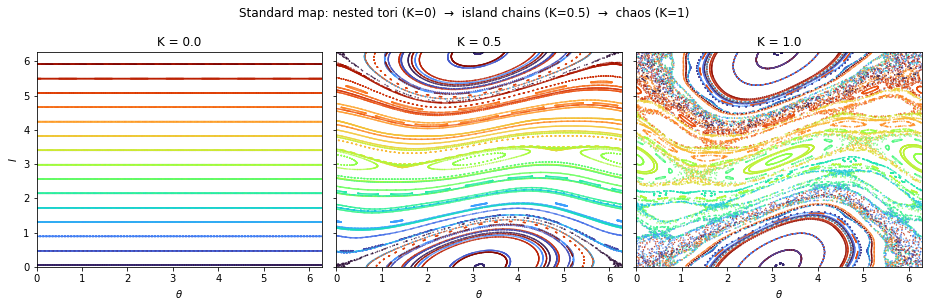

In [2]:
def standard_map(theta, I, K, n_steps):
    # Iterate the standard map n_steps times for arrays of initial conditions.
    # Returns arrays of shape (n_steps, n_orbits) with theta, I in [0, 2*pi).
    thetas, Is = [], []
    for _ in range(n_steps):
        I = (I + K * np.sin(theta)) % TWO_PI      # kick:     I' = I + K sin(theta)
        theta = (theta + I) % TWO_PI              # rotation: theta' = theta + I'
        thetas.append(theta)
        Is.append(I)
    return np.array(thetas), np.array(Is)

# Initial conditions: a few theta values x a column of I values
theta0, I0 = np.meshgrid(np.linspace(0, TWO_PI, 4, endpoint=False) + 0.1,
                         np.linspace(0, TWO_PI, 15, endpoint=False) + 0.05)
theta0, I0 = theta0.ravel(), I0.ravel()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, K in zip(axes, [0.0, 0.5, 1.0]):
    th, I = standard_map(theta0, I0, K, n_steps=500)
    colors = np.broadcast_to(np.arange(theta0.size), th.shape)   # one colour per orbit
    ax.scatter(th, I, c=colors, s=0.15, cmap="turbo", rasterized=True)
    ax.set_title(f"K = {K}")
    ax.set_xlim(0, TWO_PI); ax.set_ylim(0, TWO_PI)
    ax.set_xlabel(r"$\theta$")
axes[0].set_ylabel(r"$I$")
fig.suptitle("Standard map: nested tori (K=0)  →  island chains (K=0.5)  →  chaos (K=1)")
fig.tight_layout()
plt.show()

## 2. Poincaré–Birkhoff theorem: what happens to a resonant torus

Take an unperturbed invariant curve with **rational** winding number $\omega = n/m$ ($n, m$ coprime integers).
At $K=0$ *every* point on it is periodic with period $m$: after $m$ steps it has gone round exactly $n$ times.
Because of the twist ($\omega$ depends on $I$), curves just above it rotate a little faster and curves just below a little
slower than $n/m$, so relative to the resonant curve they drift in opposite directions.

**Poincaré–Birkhoff theorem.** Under a small area-preserving perturbation of such a twist map, the resonant curve does not
survive, but at least **two** periodic orbits of period $m$ survive (generically $2$, i.e. $2m$ points in the section).
They alternate along the former curve:

* **elliptic** (stable) points: nearby orbits circulate around them on small closed curves — the centres of the **islands**;
* **hyperbolic** (unstable) points: nearby orbits are pushed away along an unstable direction and pulled in along a
  stable one — the "X" points between islands. Their stable and unstable manifolds intersect and create a thin
  **chaotic layer** around the island chain.

The result is an alternating **island chain**: $m$ islands, $m$ hyperbolic points. Inside each island the whole
story repeats on a smaller scale (islands around islands).

**Elliptic or hyperbolic?** For a periodic point of period $m$, let $M$ be the product of the $m$ Jacobian matrices along the
orbit. Since the map preserves area, $\det M = 1$, so the two eigenvalues $\lambda_{1,2}$ satisfy $\lambda_1\lambda_2 = 1$ and
$\lambda_1+\lambda_2 = \operatorname{tr} M$. If $|\operatorname{tr} M| < 2$ they are complex, $e^{\pm i\alpha}$
(rotation → **elliptic**); if $|\operatorname{tr} M| > 2$ they are real, $\lambda$ and $1/\lambda$ (stretching → **hyperbolic**).
For the standard map, differentiating $I' = I + K\sin\theta$, $\theta' = \theta + I'$ gives the one-step Jacobian

$$
J(\theta) = \frac{\partial(\theta', I')}{\partial(\theta, I)} =
\begin{pmatrix} 1 + K\cos\theta & 1 \\ K\cos\theta & 1 \end{pmatrix}, \qquad \det J = 1 .
$$

**Example: the $\omega = 1/2$ resonance** at $I = \pi$ ($m = 2$). Two period-2 orbits survive:

* $(\theta, I) = (0, \pi) \to (\pi, \pi) \to (0,\pi)$. Check: at $\theta=0$, $I' = \pi + K\sin 0 = \pi$, $\theta' = 0+\pi = \pi$;
  at $\theta=\pi$, $I'' = \pi + K\sin\pi = \pi$, $\theta'' = \pi + \pi = 2\pi \equiv 0$.
* $(a,\ 2\pi - 2a - K\sin a) \to (-a,\ 2\pi - 2a)$, where $a$ solves $4a + K\sin a = 2\pi$ (for $K = 0$, $a = \pi/2$).
  Check: $I' = 2\pi - 2a - K\sin a + K\sin a = 2\pi-2a$, $\theta' = a + 2\pi - 2a \equiv -a$; then
  $I'' = 2\pi - 2a + K\sin(-a) = 2\pi - 2a - K\sin a$ (back to the start), $\theta'' = -a + I'' = 2\pi - 3a - K\sin a \equiv a$
  using $4a + K\sin a = 2\pi$.

The code finds $a$, computes $\operatorname{tr} M$ for both orbits and marks them on a zoom of the island chain.

orbit A: tr M = +1.6400  ->  elliptic
orbit B: tr M = +2.3626  ->  hyperbolic


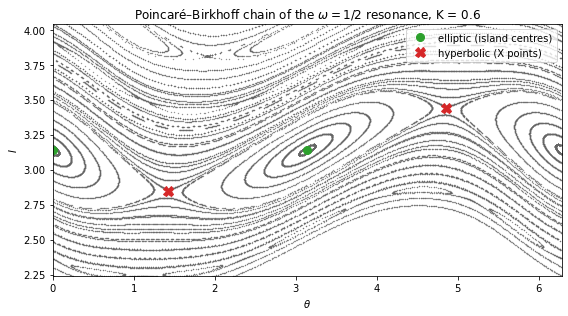

In [3]:
K = 0.6

def jacobian(theta, K):
    # One-step Jacobian d(theta', I') / d(theta, I) of the standard map
    c = K * np.cos(theta)
    return np.array([[1 + c, 1.0], [c, 1.0]])

# Orbit A: (0, pi) -> (pi, pi)
orbit_A = np.array([[0.0, np.pi], [np.pi, np.pi]])

# Orbit B: solve 4a + K sin a = 2 pi by fixed-point iteration a <- (2 pi - K sin a) / 4
a = np.pi / 2
for _ in range(100):
    a = (TWO_PI - K * np.sin(a)) / 4
orbit_B = np.array([[a, TWO_PI - 2 * a - K * np.sin(a)], [TWO_PI - a, TWO_PI - 2 * a]])

for name, orb in [("A", orbit_A), ("B", orbit_B)]:
    M = jacobian(orb[1, 0], K) @ jacobian(orb[0, 0], K)     # product over the 2-step orbit
    kind = "elliptic" if abs(np.trace(M)) < 2 else "hyperbolic"
    print(f"orbit {name}: tr M = {np.trace(M):+.4f}  ->  {kind}")

# Phase portrait near I = pi: a column of initial conditions through both orbits
I0 = np.linspace(np.pi - 0.9, np.pi + 0.9, 30)
th, I = standard_map(np.full_like(I0, 0.0), I0, K, n_steps=600)
th2, I2 = standard_map(np.full_like(I0, a), I0, K, n_steps=600)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(np.r_[th, th2], np.r_[I, I2], s=0.1, c="0.4", rasterized=True)
ax.plot(*orbit_A.T, "o", c="tab:green", ms=8, label="elliptic (island centres)")
ax.plot(*orbit_B.T, "X", c="tab:red", ms=10, label="hyperbolic (X points)")
ax.set_xlim(0, TWO_PI); ax.set_ylim(np.pi - 0.9, np.pi + 0.9)
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$I$")
ax.set_title(rf"Poincaré–Birkhoff chain of the $\omega = 1/2$ resonance, K = {K}")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 3. The Diophantine condition: "sufficiently irrational"

Why do resonances matter? Perturbation theory tries to remove the angle dependence of $H_1$ by a change of variables.
Expanding $H_1$ in a Fourier series, $H_1 = \sum_{\mathbf m} h_{\mathbf m}(\mathbf I)\, e^{i\mathbf m\cdot\boldsymbol\theta}$
(sum over integer vectors $\mathbf m \ne 0$), the generating function of that change of variables has coefficients

$$
\frac{h_{\mathbf m}}{\mathbf m\cdot\boldsymbol\omega} .
$$

These **small denominators** vanish on resonant tori ($\mathbf m\cdot\boldsymbol\omega = 0$) and are tiny on tori close to
resonance, so the series can diverge. KAM theory works on tori where the denominators are bounded away from zero
in a controlled way.

For a map with a single winding number $\omega$ (one degree of freedom, as in the standard map and the kicked top), the
resonances are $\omega = n/m$ and the denominators are $m\omega - n$. The frequency $\omega$ is called **Diophantine** if there
are constants $\gamma > 0$ and $\tau \ge 1$ such that

$$
|\,m\,\omega - n\,| \;\ge\; \frac{\gamma}{|m|^{\tau}}
\qquad \text{for all integers } n \text{ and all integers } m \neq 0 .
$$

In words: $\omega$ cannot be approximated "too well" by rationals $n/m$; the better the approximation one wants, the larger
the denominator $m$ must be. ($\gamma$ sets how far from each resonance one must stay; $\tau$ how fast that distance may shrink
with $m$.) For $d$ frequencies the condition reads $|\mathbf m\cdot\boldsymbol\omega| \ge \gamma/|\mathbf m|^\tau$ with $\tau \ge d-1$.

* Rationals violate it: for $\omega = n_0/m_0$, the choice $m=m_0$, $n=n_0$ gives $0$.
* Almost every real number (all except a set of measure zero) is Diophantine for $\tau > 1$ and some $\gamma$,
  which is why the surviving tori fill most of phase space.
* The KAM theorem guarantees survival of tori with Diophantine $\omega$ as long as $\varepsilon$ is small compared with
  (roughly) $\gamma^2$: tori with a larger $\gamma$ survive larger perturbations.

**A simple test.** For $\tau = 1$, the condition says that $m\,\|m\omega\|$ stays above $\gamma$ for every $m \ge 1$, where
$\|x\|$ is the distance from $x$ to the nearest integer (so $\|m\omega\| = \min_n |m\omega - n|$). The figure plots, for a few
numbers $\omega$, the smallest value of $m'\,\|m'\omega\|$ over all denominators $m' \le m$, for $m$ up to $10^5$.
If this curve stays above a positive constant, $\omega$ satisfies the condition with $\tau = 1$ and $\gamma$ equal to that
constant; each downward step marks a rational $n/m$ that approximates $\omega$ unusually well.

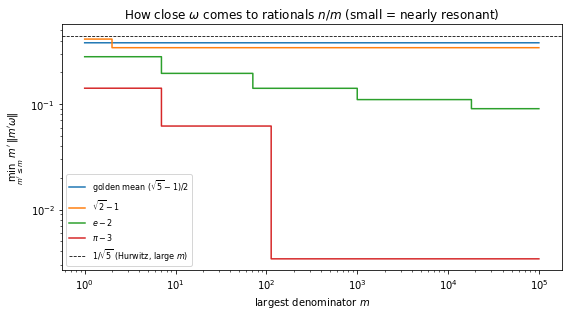

In [4]:
def dist_to_int(x):
    # ||x||: distance from x to the nearest integer
    return np.abs(x - np.round(x))

m = np.arange(1, 100_001)
numbers = {
    r"golden mean $(\sqrt{5}-1)/2$": (np.sqrt(5) - 1) / 2,
    r"$\sqrt{2}-1$":                 np.sqrt(2) - 1,
    r"$e-2$":                        np.e - 2,
    r"$\pi-3$":                      np.pi - 3,
}

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, w in numbers.items():
    worst = np.minimum.accumulate(m * dist_to_int(m * w))   # min over m' <= m of m' ||m' w||
    ax.step(m, worst, where="post", label=label)
ax.axhline(1 / np.sqrt(5), c="k", lw=0.8, ls="--", label=r"$1/\sqrt{5}$ (Hurwitz, large $m$)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"largest denominator $m$")
ax.set_ylabel(r"$\min_{m' \leq m}\; m'\,\|m'\omega\|$")
ax.set_title("How close $\\omega$ comes to rationals $n/m$ (small = nearly resonant)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

Reading the figure: $\pi - 3$ drops sharply at $m = 7$ ($\pi \approx 22/7$) and at $m = 113$ ($\pi \approx 355/113$),
and $e - 2$ keeps stepping down (slowly, without bound): these numbers come anomalously close to some rationals.
$\sqrt2 - 1$ and the golden mean level off at positive constants, so they are Diophantine with $\tau = 1$; the golden mean
levels off highest. It is the number that stays farthest from all rationals, which is the topic of the next section.

## 4. Tori with golden-ratio frequencies

### Continued fractions

Every real number $\omega \in (0,1)$ has a **continued-fraction expansion**

$$
\omega = \cfrac{1}{a_1 + \cfrac{1}{a_2 + \cfrac{1}{a_3 + \cdots}}} \equiv [0; a_1, a_2, a_3, \dots],
\qquad a_j \in \{1, 2, 3, \dots\}.
$$

The coefficients are obtained by repeatedly taking the integer part and inverting the remainder:
$a_1 = \lfloor 1/\omega \rfloor$, then $x_1 = 1/\omega - a_1$, $a_2 = \lfloor 1/x_1 \rfloor$, and so on
($\lfloor\cdot\rfloor$ is the integer part). Truncating after $a_j$ gives the **convergents** $p_j/q_j$, the best rational
approximations of $\omega$. They satisfy

$$
\left|\omega - \frac{p_j}{q_j}\right| = \frac{1}{q_j\,(q_j\,\xi_{j+1} + q_{j-1})},
\qquad \xi_{j+1} = [a_{j+1}; a_{j+2}, \dots] ,
$$

with $q_{j-1}$ the previous denominator, so roughly $|\omega - p_j/q_j| \approx 1/(a_{j+1} q_j^2)$:
**a large coefficient $a_{j+1}$ means an unusually good rational approximation** (e.g. $\pi - 3 = [0; 7, 15, 1, 292, \dots]$,
and $a_4 = 292$ produces $355/113$).

### The golden mean is the "most irrational" number

The golden mean $\omega_g = (\sqrt5 - 1)/2 \approx 0.618$ satisfies $\omega_g^2 + \omega_g = 1$, i.e.
$\omega_g = 1/(1 + \omega_g)$. Substituting this relation into itself again and again gives

$$
\omega_g = \cfrac{1}{1 + \cfrac{1}{1 + \cfrac{1}{1 + \cdots}}} = [0; 1, 1, 1, \dots] ,
$$

all coefficients equal to $1$, the smallest possible value. So every convergent is as poor an approximation as possible.
The convergents are ratios of consecutive **Fibonacci numbers** $F_j$ ($F_1 = F_2 = 1$, $F_{j+1} = F_j + F_{j-1}$):
$1/1, 1/2, 2/3, 3/5, 5/8, 8/13, \dots$, and $|\omega_g - F_j/F_{j+1}| \approx 1/(\sqrt5\,F_{j+1}^2)$. Hurwitz's theorem states that
$1/\sqrt5$ is the best possible constant for any irrational number, and that it is attained by $\omega_g$ and numbers
equivalent to it (continued fraction ending in $1,1,1,\dots$). In the language of Sec. 3, $\omega_g$ is Diophantine with
$\tau = 1$ and the **largest possible** $\gamma$.

### Consequence for KAM tori

Since the golden torus is the farthest from all resonances, it is the most robust one: in the standard map the invariant curve
with winding number $\omega_g$ (and its mirror image $1-\omega_g$) is the **last spanning torus to be destroyed**, at
$K_c \approx 0.9716$ (Greene's residue criterion, 1979). For $K > K_c$ no curve separates low from high $I$, and chaotic
orbits diffuse in $I$ — compare the $K = 1.0$ panel of Sec. 1. In mixed systems such as the kicked top, the boundary tori of
the regular islands are likewise typically "noble" (golden-like) tori.

The figure compares how fast the convergents approach $\omega_g$ and $\pi - 3$: the golden convergents (Fibonacci ratios)
lie exactly on the slowest line $1/(\sqrt5\,q^2)$, while $\pi - 3$ has convergents that jump far below it.

golden mean   a = [1, 1, 1, 1, 1, 1, 1, 1]   convergents: ['1/1', '1/2', '2/3', '3/5', '5/8', '8/13', '13/21', '21/34']
$\pi-3$       a = [7, 15, 1, 292, 1]   convergents: ['1/7', '15/106', '16/113', '4687/33102', '4703/33215']


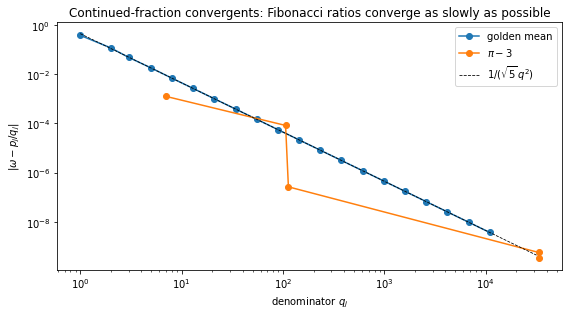

In [5]:
def convergents(w, n_terms):
    # Continued-fraction coefficients a_j and convergents p_j/q_j of w in (0, 1)
    a = []
    x = w
    for _ in range(n_terms):
        x = 1 / x
        a.append(int(np.floor(x)))
        x = x - a[-1]
    # Recurrence: p_j = a_j p_{j-1} + p_{j-2}, q_j = a_j q_{j-1} + q_{j-2}, with (p,q)_{-1} = (1,0), (p,q)_0 = (0,1)
    p, q = [1, 0], [0, 1]
    for aj in a:
        p.append(aj * p[-1] + p[-2])
        q.append(aj * q[-1] + q[-2])
    return a, np.array(p[2:]), np.array(q[2:])

golden = (np.sqrt(5) - 1) / 2
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, w, n in [(r"golden mean", golden, 20), (r"$\pi-3$", np.pi - 3, 5)]:
    a, p, q = convergents(w, n)
    print(f"{label:12s}  a = {a[:8]}   convergents: {[f'{pi}/{qi}' for pi, qi in zip(p[:8], q[:8])]}")
    ax.loglog(q, np.abs(w - p / q), "o-", label=label)
qq = np.logspace(0, 4.5, 50)
ax.loglog(qq, 1 / (np.sqrt(5) * qq**2), "k--", lw=0.8, label=r"$1/(\sqrt{5}\,q^2)$")
ax.set_xlabel(r"denominator $q_j$")
ax.set_ylabel(r"$|\omega - p_j/q_j|$")
ax.set_title("Continued-fraction convergents: Fibonacci ratios converge as slowly as possible")
ax.legend()
fig.tight_layout()
plt.show()

## Summary

| concept | statement | where it shows up |
|---|---|---|
| KAM | Diophantine tori of $H_0 + \varepsilon H_1$ survive small $\varepsilon$ | smooth curves in Sec. 1 and in kicked-top portraits at small $k$ |
| Poincaré–Birkhoff | a resonant torus $n/m$ breaks into $m$ elliptic islands + $m$ hyperbolic points | island chains, Sec. 2 |
| Diophantine | $\lvert m\omega - n\rvert \ge \gamma/\lvert m\rvert^\tau$: hard to approximate by rationals | Sec. 3 |
| golden torus | $[0;1,1,1,\dots]$ is the most irrational number, last torus to break ($K_c \approx 0.9716$) | Sec. 4 |